# MS COCO multi-label classification

[**attention**: we write and run this ipynb file on the google colab, so just use colab if you want to test this file ]

In this lab, we compared four transfer-learning setups for predicting the 80 object categories in the course MS COCO dataset. An image can have several labels, so we treated this as a multi-label problem. We used the course archive for training and ImageNet-pretrained TorchVision weights as starting points.

We used the same 52,000/13,000 training/validation split for all four methods. For each method, we chose the checkpoint epoch and a single classification threshold using validation F1. We selected the final model from that comparison, then generated predictions for the 4,952 unlabelled test images. The test-only server results are reported at the end.

## 1. Setup and rerunning the notebook

For a fresh run, open this file in Google Colab, select a GPU runtime (we used a T4), and run the cells from top to bottom. The notebook mounts the runner's own Google Drive and writes checkpoints, histories, plots, and JSON predictions to `MyDrive/IAV_MS_COCO`. Use an empty output folder for a completely fresh experiment. Colab will ask for Drive access when the first code cell runs.

The dataset is downloaded from the course URL(i.e. moodle page) and extracted to Colab's local disk. Pretrained model weights also need an internet connection. Our full A-D training took roughly an hour on a T4; hardware and package versions can change the runtime and final decimals. The optional course-server request is disabled by default, so Colab's **Run all** does not send a submission.

In the code cell below, we import the required libraries, set random seeds, check GPU availability, and mount Google Drive. We save checkpoints, training histories, and predictions in Drive so that the results remain available after the Colab session ends.

In [1]:
import json, os, random, shutil, subprocess, time, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
import torchvision
from google.colab import drive

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'Select Runtime > Change runtime type > GPU before training.'
drive.mount('/content/drive')
OUT_DIR = Path('/content/drive/MyDrive/IAV_MS_COCO')
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ("person", "bicycle", "car", "motorcycle", "airplane", "bus", "train", "truck", "boat", "traffic light",
           "fire hydrant", "stop sign", "parking meter", "bench", "bird", "cat", "dog", "horse", "sheep", "cow",
           "elephant", "bear", "zebra", "giraffe", "backpack", "umbrella", "handbag", "tie", "suitcase", "frisbee",
           "skis", "snowboard", "sports ball", "kite", "baseball bat", "baseball glove", "skateboard", "surfboard",
           "tennis racket", "bottle", "wine glass", "cup", "fork", "knife", "spoon", "bowl", "banana", "apple",
           "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza", "donut", "cake", "chair", "couch",
           "potted plant", "bed", "dining table", "toilet", "tv", "laptop", "mouse", "remote", "keyboard", "cell phone",
           "microwave", "oven", "toaster", "sink", "refrigerator", "book", "clock", "vase", "scissors", "teddy bear",
           "hair drier", "toothbrush")
NUM_CLASSES = len(CLASSES)
print('Python/PyTorch/TorchVision:', os.sys.version.split()[0], torch.__version__, torchvision.__version__)
print('Accelerator:', torch.cuda.get_device_name(0))
print('Drive output folder:', OUT_DIR)


Mounted at /content/drive
Python/PyTorch/TorchVision: 3.13.15 2.11.0+cu130 0.26.0+cu130
Accelerator: Tesla T4
Drive output folder: /content/drive/MyDrive/IAV_MS_COCO


## 2. Download and check the course dataset

The course ZIP is about 1.84 GB. We keep the images on Colab's local disk because loading many small files directly from Drive is slow. This cell reuses the extracted files if they are still there; otherwise it downloads the archive, checks it, and extracts it. The expected counts below are a quick check that the train labels and test images are in the right places.

In [2]:
DATA_URL = 'https://www.creatis.insa-lyon.fr/~kechichian/IAV/ms-coco.zip'
ARCHIVE = Path('/content/ms-coco.zip')
DATA_ROOT = Path('/content/data/ms-coco')
TRAIN_IMAGE_DIR = DATA_ROOT / 'images/train'
TRAIN_LABEL_DIR = DATA_ROOT / 'labels/train'
TEST_IMAGE_DIR = DATA_ROOT / 'images/test'
EXPECTED_ARCHIVE_BYTES = 1_836_661_512  # observed from the course server on 8 October 2026

already_extracted = (TRAIN_IMAGE_DIR.exists() and TRAIN_LABEL_DIR.exists() and TEST_IMAGE_DIR.exists()
                     and len(list(TRAIN_IMAGE_DIR.glob('*.jpg'))) == 65_000
                     and len(list(TRAIN_LABEL_DIR.glob('*.cls'))) == 65_000
                     and len(list(TEST_IMAGE_DIR.glob('*.jpg'))) == 4_952)
if not already_extracted:
    if not ARCHIVE.exists() or ARCHIVE.stat().st_size != EXPECTED_ARCHIVE_BYTES:
        subprocess.run(['wget', '-c', '--progress=dot:giga', '-O', str(ARCHIVE), DATA_URL], check=True)
    assert ARCHIVE.stat().st_size == EXPECTED_ARCHIVE_BYTES, 'Unexpected archive size; check the download.'
    with zipfile.ZipFile(ARCHIVE) as zf:
        assert zf.testzip() is None, 'ZIP checksum validation failed.'
        zf.extractall('/content/data')

train_files = sorted(TRAIN_IMAGE_DIR.glob('*.jpg'))
test_files = sorted(TEST_IMAGE_DIR.glob('*.jpg'))
label_files = sorted(TRAIN_LABEL_DIR.glob('*.cls'))
assert len(train_files) == len(label_files) == 65_000
assert len(test_files) == 4_952
assert {p.stem for p in train_files} == {p.stem for p in label_files}
print('Train images / label files / test images:', len(train_files), len(label_files), len(test_files))
print('Example image:', train_files[0].name, 'labels:', (TRAIN_LABEL_DIR / (train_files[0].stem + '.cls')).read_text().split())
print('Free local disk (GiB):', round(shutil.disk_usage('/content').free / 2**30, 1))


Train images / label files / test images: 65000 65000 4952
Example image: 000000000009.jpg labels: ['45', '49', '50']
Free local disk (GiB): 66.4


## 3. Labels, split, and class imbalance

Each `.cls` file contains the zero-based IDs of the classes present in one image. We turn it into an 80-element multi-hot vector and make a fixed, seeded 80/20 split. Every method sees the same 52,000 training images and 13,000 validation images. We calculate positive loss weights from the training portion only and cap them at 20 so very rare classes do not dominate the loss.

In [3]:
image_paths = train_files
targets = np.zeros((len(image_paths), NUM_CLASSES), dtype=np.float32)
for i, path in enumerate(image_paths):
    ids = [int(x) for x in (TRAIN_LABEL_DIR / (path.stem + '.cls')).read_text().split()]
    assert all(0 <= x < NUM_CLASSES for x in ids)
    targets[i, ids] = 1.0

permutation = np.random.default_rng(SEED).permutation(len(image_paths))
split_at = int(0.8 * len(permutation))
train_indices = permutation[:split_at].tolist()
val_indices = permutation[split_at:].tolist()
np.savez(OUT_DIR / 'split_seed42.npz', train_indices=train_indices, val_indices=val_indices)
train_count = targets[train_indices].sum(axis=0)
val_count = targets[val_indices].sum(axis=0)
assert np.all(train_count > 0) and np.all(val_count > 0), 'A class is absent; reconsider the split.'
pos_weight = np.clip((len(train_indices) - train_count) / np.maximum(train_count, 1), 1, 20)
class_counts = pd.DataFrame({'class_id': np.arange(NUM_CLASSES), 'class_name': CLASSES,
                             'train_positives': train_count.astype(int), 'val_positives': val_count.astype(int),
                             'loss_pos_weight': pos_weight.round(2)})
display(class_counts.sort_values('train_positives').head(10))
print('Train/validation:', len(train_indices), len(val_indices))
print('Mean labels per image:', round(float(targets.sum(axis=1).mean()), 3))


,class_id,class_name,train_positives,val_positives,loss_pos_weight
78,78,hair drier,76,26,20.0
70,70,toaster,97,20,20.0
12,12,parking meter,335,61,20.0
21,21,bear,414,102,20.0
76,76,scissors,445,110,20.0
79,79,toothbrush,452,109,20.0
52,52,hot dog,534,133,20.0
18,18,sheep,647,162,20.0
68,68,microwave,677,155,20.0
54,54,donut,690,166,20.0


Train/validation: 52000 13000
Mean labels per image: 2.926


## 4. Image preprocessing and data loaders

We resize whole images to 224 x 224 so an annotated object is not accidentally cropped away. This distorts some aspect ratios, but it keeps the labels consistent with the image. We use a random horizontal flip during training and deterministic preprocessing for validation and test. The normalization matches the ImageNet-pretrained weights.

In [4]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)
train_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
                                      transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                                     transforms.Normalize(MEAN, STD)])

class LabeledCOCO(Dataset):
    def __init__(self, paths, target_matrix, indices, transform):
        self.paths, self.target_matrix, self.indices, self.transform = paths, target_matrix, list(indices), transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, item):
        index = self.indices[item]
        with Image.open(self.paths[index]) as image:
            pixels = self.transform(image.convert('RGB'))
        return pixels, torch.from_numpy(self.target_matrix[index])

class UnlabeledCOCO(Dataset):
    def __init__(self, paths, transform):
        self.paths, self.transform = list(paths), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, item):
        path = self.paths[item]
        with Image.open(path) as image:
            pixels = self.transform(image.convert('RGB'))
        return pixels, path.stem

train_dataset = LabeledCOCO(image_paths, targets, train_indices, train_transform)
val_dataset = LabeledCOCO(image_paths, targets, val_indices, eval_transform)
test_dataset = UnlabeledCOCO(test_files, eval_transform)
def make_loader(dataset, batch_size, shuffle=False):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=2,
                      pin_memory=True, persistent_workers=False)

sample_x, sample_y = train_dataset[0]
assert sample_x.shape == (3, 224, 224) and sample_y.shape == (80,)
print('Sample tensor / positive class IDs:', tuple(sample_x.shape), torch.where(sample_y > 0)[0].tolist())


Sample tensor / positive class IDs: (3, 224, 224) [0, 1, 2, 7, 26, 36]


## 5. Models and loss

In this step, we choose 4 models (we name them as Method A-D)

Each network produces 80 logits, one per class. In Method A (ResNet-18) and Method B (MobileNetV3-Large), we freeze the backbone and train a new classifier. Method C starts from A's selected checkpoint and fine-tunes its last residual block and classifier. Method D is described below.

An image can contain several classes at the same time, so we treat each class as a separate yes-or-no prediction. BCEWithLogitsLoss applies a binary classification loss to each logit and its corresponding label. 

Softmax would make the classes compete with one another, while argmax would return just one class; neither matches this multi-label task,so here we dont use them.

In [5]:
def build_model(architecture, pretrained=True):
    if architecture == 'resnet18':
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        net = models.resnet18(weights=weights)
        net.fc = nn.Linear(net.fc.in_features, NUM_CLASSES)
    elif architecture == 'mobilenet_v3_large':
        weights = models.MobileNet_V3_Large_Weights.DEFAULT if pretrained else None
        net = models.mobilenet_v3_large(weights=weights)
        net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, NUM_CLASSES)
    else:
        raise ValueError(architecture)
    return net

def prepare_model(experiment_key):
    if experiment_key == 'A_resnet18_frozen':
        net = build_model('resnet18')
        for parameter in net.parameters(): parameter.requires_grad = False
        for parameter in net.fc.parameters(): parameter.requires_grad = True
    elif experiment_key == 'B_mobilenet_frozen':
        net = build_model('mobilenet_v3_large')
        for parameter in net.parameters(): parameter.requires_grad = False
        for parameter in net.classifier[-1].parameters(): parameter.requires_grad = True
    elif experiment_key == 'C_resnet18_finetune':
        net = build_model('resnet18', pretrained=False)
        parent = torch.load(OUT_DIR / 'A_resnet18_frozen.pt', map_location='cpu', weights_only=False)
        net.load_state_dict(parent['state_dict'])
        for parameter in net.parameters(): parameter.requires_grad = False
        for parameter in net.layer4.parameters(): parameter.requires_grad = True
        for parameter in net.fc.parameters(): parameter.requires_grad = True
    else:
        raise ValueError(experiment_key)
    return net.to(DEVICE)

criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, dtype=torch.float32, device=DEVICE))
print('Positive loss weights:', float(pos_weight.min()), 'to', float(pos_weight.max()))


Positive loss weights: 1.0 to 20.0


## 6. Validation metric and threshold

We use the course-style F1(i.e. weighted F1) based on precision and recall weighted by inverse class frequency. This gives rare classes more influence. We also report macro F1 and micro F1 to see whether a gain holds across classes and across all individual decisions.

We turn class probabilities into predictions using a threshold. For each epoch, we evaluate several thresholds on the validation set and retain the one with the highest course-weighted F1. We compare epochs using their own validation-selected thresholds.

The global threshold grid is 0.10 to 0.95 in steps of 0.025. We search it at **each epoch**, then retain the epoch/threshold pair with the highest validation weighted F1. This is why changing the threshold can also change the chosen epoch. We use the validation set for this choice; test labels and test-only scores do not enter the search.

In [6]:
THRESHOLDS = np.round(np.arange(0.10, 0.951, 0.025), 3)

def compute_metrics(truth, probabilities, threshold):
    actual = truth >= 0.5
    predicted = probabilities >= threshold
    tp = np.logical_and(predicted, actual).sum(axis=0).astype(float)
    fp = np.logical_and(predicted, ~actual).sum(axis=0).astype(float)
    fn = np.logical_and(~predicted, actual).sum(axis=0).astype(float)
    precision = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    class_f1 = np.divide(2 * precision * recall, precision + recall,
                         out=np.zeros_like(tp), where=(precision + recall) > 0)
    frequency = tp + fn
    inverse = np.divide(1.0, frequency, out=np.zeros_like(frequency), where=frequency > 0)
    weights = inverse / inverse.sum()
    weighted_precision = float(np.dot(weights, precision))
    weighted_recall = float(np.dot(weights, recall))
    weighted_f1 = (2 * weighted_precision * weighted_recall / (weighted_precision + weighted_recall)
                   if weighted_precision + weighted_recall else 0.0)
    micro_precision = tp.sum() / max(tp.sum() + fp.sum(), 1)
    micro_recall = tp.sum() / max(tp.sum() + fn.sum(), 1)
    micro_f1 = (2 * micro_precision * micro_recall / (micro_precision + micro_recall)
                if micro_precision + micro_recall else 0.0)
    return {'weighted_f1': weighted_f1, 'weighted_precision': weighted_precision,
            'weighted_recall': weighted_recall, 'macro_f1': float(class_f1.mean()),
            'micro_f1': float(micro_f1), 'class_f1': class_f1,
            'class_precision': precision, 'class_recall': recall}

def choose_threshold(truth, probabilities):
    candidates = [(float(t), compute_metrics(truth, probabilities, float(t))) for t in THRESHOLDS]
    return max(candidates, key=lambda item: item[1]['weighted_f1'])


## 7. Training loop

This cell defines one training epoch, validation, and the complete experiment loop. We record the metrics for each epoch, save the checkpoint with the best validation F1, and stop early when validation performance no longer improves. Mixed precision makes GPU training more efficient.


In [7]:
def train_one_epoch(net, loader, optimizer, scaler):
    net.train()
    for module in net.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()  # preserve ImageNet running mean/variance
    total_loss, total_images = 0.0, 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda', enabled=True):
            logits = net(images)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += float(loss.detach()) * len(images)
        total_images += len(images)
    return total_loss / total_images

@torch.inference_mode()
def evaluate(net, loader):
    net.eval()
    losses, probabilities, truths, total_images = 0.0, [], [], 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', enabled=True):
            logits = net(images)
            loss = criterion(logits, labels)
        losses += float(loss) * len(images)
        total_images += len(images)
        probabilities.append(torch.sigmoid(logits.float()).cpu().numpy())
        truths.append(labels.cpu().numpy())
    return losses / total_images, np.concatenate(probabilities), np.concatenate(truths)

def run_experiment(spec):
    key = spec['key']
    net = prepare_model(key)
    if key == 'C_resnet18_finetune':
        optimizer = torch.optim.AdamW([{'params': net.layer4.parameters(), 'lr': 1e-4},
                                       {'params': net.fc.parameters(), 'lr': 3e-4}], weight_decay=1e-4)
    else:
        optimizer = torch.optim.AdamW((p for p in net.parameters() if p.requires_grad),
                                      lr=spec['lr'], weight_decay=1e-4)
    scaler = torch.amp.GradScaler('cuda')
    train_loader = make_loader(train_dataset, spec['batch_size'], shuffle=True)
    val_loader = make_loader(val_dataset, spec['batch_size'])
    checkpoint_path = OUT_DIR / f'{key}.pt'
    best_f1, no_improvement, rows = -1.0, 0, []
    for epoch in range(1, spec['max_epochs'] + 1):
        started = time.time()
        train_loss = train_one_epoch(net, train_loader, optimizer, scaler)
        val_loss, probabilities, truth = evaluate(net, val_loader)
        threshold, metrics = choose_threshold(truth, probabilities)
        row = {'experiment': key, 'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
               'threshold': threshold, 'weighted_f1': metrics['weighted_f1'],
               'macro_f1': metrics['macro_f1'], 'micro_f1': metrics['micro_f1'],
               'minutes': (time.time() - started) / 60}
        rows.append(row)
        print(pd.DataFrame([row]).round(4).to_string(index=False), flush=True)
        if metrics['weighted_f1'] > best_f1 + 1e-4:
            best_f1, no_improvement = metrics['weighted_f1'], 0
            torch.save({'experiment': key, 'architecture': spec['architecture'], 'epoch': epoch,
                        'threshold': threshold, 'validation_metrics': {k: v for k, v in metrics.items() if not k.startswith('class_')},
                        'state_dict': net.state_dict(), 'seed': SEED}, checkpoint_path)
        else:
            no_improvement += 1
        pd.DataFrame(rows).to_csv(OUT_DIR / f'{key}_history.csv', index=False)
        if no_improvement >= 2:
            print('Early stopping after two epochs without validation improvement.')
            break
    del net, optimizer, scaler
    torch.cuda.empty_cache()
    return pd.DataFrame(rows)


## 8. Baselines: methods A-C

A and B compare two pretrained feature extractors with only a new classifier trained. C tests whether another stage of fine-tuning improves on A. These three were our first experiments. They use the same split, labels, loss, augmentation, threshold grid, and five-epoch maximum. The displayed output is from our completed run; on a fresh Drive account, this cell trains them again.

In [ ]:
EXPERIMENTS = [
    {'key': 'A_resnet18_frozen', 'architecture': 'resnet18', 'batch_size': 128, 'lr': 1e-3, 'max_epochs': 5},
    {'key': 'B_mobilenet_frozen', 'architecture': 'mobilenet_v3_large', 'batch_size': 128, 'lr': 1e-3, 'max_epochs': 5},
    {'key': 'C_resnet18_finetune', 'architecture': 'resnet18', 'batch_size': 64, 'lr': None, 'max_epochs': 5},
]
histories = {}
for spec in EXPERIMENTS:
    print('\nStarting', spec['key'], flush=True)
    histories[spec['key']] = run_experiment(spec)



Starting A_resnet18_frozen
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 131MB/s]


       experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
A_resnet18_frozen      1      0.4829    0.4148       0.85       0.3901    0.4971    0.5554   2.5871
       experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
A_resnet18_frozen      2      0.3978    0.4016       0.85       0.4356    0.5156    0.5664   2.4518
       experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
A_resnet18_frozen      3      0.3824    0.3964      0.825        0.465    0.5202    0.5667   2.3963
       experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
A_resnet18_frozen      4      0.3735    0.3937      0.875       0.4664    0.5264    0.5711   2.3885
       experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
A_resnet18_frozen      5      0.3681    0.3896        0.9       0.4619    0.5275    0.5798   2.4014


100%|██████████| 21.1M/21.1M [00:00<00:00, 168MB/s]


        experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
B_mobilenet_frozen      1      0.4533    0.3656      0.725       0.4709    0.5441    0.5784   2.4786
        experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
B_mobilenet_frozen      2      0.3482    0.3469      0.875        0.495    0.5838    0.6249   2.3812
        experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
B_mobilenet_frozen      3      0.3279    0.3422      0.875       0.4975    0.5871    0.6297   2.4057
        experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
B_mobilenet_frozen      4      0.3169    0.3402      0.925       0.4905    0.5795    0.6206   2.3712
        experiment  epoch  train_loss  val_loss  threshold  weighted_f1  macro_f1  micro_f1  minutes
B_mobilenet_frozen      5      0.3098    0.3395      0.925       0.4728    0.5816    0.6254

### Method D: fine-tuning the last stage of ConvNeXt-Tiny

ConvNeXt is a modern convolutional network that extracts image features in stages using design choices such as large-kernel depthwise convolutions.ConvNeXt-Tiny is a lighter version of ConvNeXt,and we will use it in method D

For method D, we start from ImageNet-1K pretrained weights,D uses the same data split, 224 x 224 images, loss, horizontal flip, validation metric, and threshold grid. We replace the classifier with 80 outputs, freeze the earlier feature stages, and train the last feature stage and classifier at separate learning rates. This lets us compare D with A-C using the validation set.

If its history and checkpoint are already in the runner's Drive folder, the cell below restores them and shows the five-epoch history;With an empty folder, it trains D.

In [13]:
# Resume the completed A-C results if Colab assigned a fresh runtime.
if 'EXPERIMENTS' not in globals():
    EXPERIMENTS = [
        {'key': 'A_resnet18_frozen', 'architecture': 'resnet18', 'batch_size': 128},
        {'key': 'B_mobilenet_frozen', 'architecture': 'mobilenet_v3_large', 'batch_size': 128},
        {'key': 'C_resnet18_finetune', 'architecture': 'resnet18', 'batch_size': 64},
    ]
if 'histories' not in globals():
    histories = {spec['key']: pd.read_csv(OUT_DIR / f"{spec['key']}_history.csv")
                 for spec in EXPERIMENTS}

# The original builder remains available for A, B and C checkpoints.
_base_build_model = globals().get('_base_build_model', build_model)
def build_model(architecture, pretrained=True):
    if architecture == 'convnext_tiny':
        weights = models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.convnext_tiny(weights=weights)
        net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, NUM_CLASSES)
        return net
    return _base_build_model(architecture, pretrained)

D_SPEC = {'key': 'D_convnext_tiny_finetune', 'architecture': 'convnext_tiny',
          'batch_size': 32, 'max_epochs': 5}
if not any(spec['key'] == D_SPEC['key'] for spec in EXPERIMENTS):
    EXPERIMENTS.append(D_SPEC)

def run_convnext_experiment(spec):
    # Give D its own seed so its initialization does not depend on A-C execution history.
    random.seed(SEED + 4)
    np.random.seed(SEED + 4)
    torch.manual_seed(SEED + 4)
    torch.cuda.manual_seed_all(SEED + 4)
    net = build_model('convnext_tiny', pretrained=True).to(DEVICE)
    for parameter in net.parameters():
        parameter.requires_grad = False
    for parameter in net.features[-1].parameters():
        parameter.requires_grad = True
    for parameter in net.classifier[-1].parameters():
        parameter.requires_grad = True
    optimizer = torch.optim.AdamW([
        {'params': net.features[-1].parameters(), 'lr': 5e-5},
        {'params': net.classifier[-1].parameters(), 'lr': 3e-4}
    ], weight_decay=1e-4)
    scaler = torch.amp.GradScaler('cuda')
    train_loader = make_loader(train_dataset, spec['batch_size'], shuffle=True)
    val_loader = make_loader(val_dataset, spec['batch_size'])
    best_f1, no_improvement, rows = -1.0, 0, []
    checkpoint_path = OUT_DIR / f"{spec['key']}.pt"
    for epoch in range(1, spec['max_epochs'] + 1):
        started = time.time()
        train_loss = train_one_epoch(net, train_loader, optimizer, scaler)
        val_loss, probabilities, truth = evaluate(net, val_loader)
        threshold, metrics = choose_threshold(truth, probabilities)
        row = {'experiment': spec['key'], 'epoch': epoch,
               'train_loss': train_loss, 'val_loss': val_loss,
               'threshold': threshold, 'weighted_f1': metrics['weighted_f1'],
               'macro_f1': metrics['macro_f1'], 'micro_f1': metrics['micro_f1'],
               'minutes': (time.time() - started) / 60}
        rows.append(row)
        print(pd.DataFrame([row]).round(4).to_string(index=False), flush=True)
        if metrics['weighted_f1'] > best_f1 + 1e-4:
            best_f1, no_improvement = metrics['weighted_f1'], 0
            torch.save({'experiment': spec['key'], 'architecture': 'convnext_tiny',
                        'epoch': epoch, 'threshold': threshold,
                        'validation_metrics': {k: v for k, v in metrics.items()
                                               if not k.startswith('class_')},
                        'state_dict': net.state_dict(), 'seed': SEED + 4}, checkpoint_path)
        else:
            no_improvement += 1
        pd.DataFrame(rows).to_csv(OUT_DIR / f"{spec['key']}_history.csv", index=False)
        if no_improvement >= 2:
            print('Early stopping after two epochs without validation improvement.')
            break
    del net, optimizer, scaler
    torch.cuda.empty_cache()
    return pd.DataFrame(rows)

d_history_path = OUT_DIR / f"{D_SPEC['key']}_history.csv"
d_checkpoint_path = OUT_DIR / f"{D_SPEC['key']}.pt"
if d_history_path.exists() and d_checkpoint_path.exists():
    d_history = pd.read_csv(d_history_path)
    d_best = d_history.loc[d_history['weighted_f1'].idxmax()]
    d_checkpoint = torch.load(d_checkpoint_path, map_location='cpu', weights_only=False)
    assert d_checkpoint['epoch'] == int(d_best['epoch'])
    assert abs(d_checkpoint['validation_metrics']['weighted_f1'] - float(d_best['weighted_f1'])) < 1e-4
    histories[D_SPEC['key']] = d_history
    print('Reused completed D training:', len(d_history), 'epochs; best epoch', d_checkpoint['epoch'],
          'validation weighted F1', round(d_checkpoint['validation_metrics']['weighted_f1'], 4))
else:
    histories[D_SPEC['key']] = run_convnext_experiment(D_SPEC)

display(histories[D_SPEC['key']].round(4))

Reused completed D training: 5 epochs; best epoch 4 validation weighted F1 0.5866


,experiment,epoch,train_loss,val_loss,threshold,weighted_f1,macro_f1,micro_f1,minutes
0,D_convnext_tiny_finetune,1,0.3698,0.2833,0.900,0.5732,0.6435,0.6720,3.2497
1,D_convnext_tiny_finetune,2,0.2579,0.2674,0.925,0.5699,0.6702,0.6969,3.0089
2,D_convnext_tiny_finetune,3,0.2188,0.2678,0.875,0.5736,0.6776,0.7037,2.9830
3,D_convnext_tiny_finetune,4,0.1867,0.2775,0.925,0.5866,0.6822,0.7118,2.9361
4,D_convnext_tiny_finetune,5,0.1595,0.2947,0.875,0.5758,0.6853,0.7106,2.9088


## 9. Compare methods on validation data

 We compare the best validation result of each method and select the final model by validation-weighted F1. Macro and micro F1 and the loss curves help us interpret that choice. We save the selected method, epoch, and threshold in `selection.json` before test prediction.

,experiment,epoch,threshold,weighted_f1,macro_f1,micro_f1,val_loss
0,D_convnext_tiny_finetune,4,0.925,0.5866,0.6822,0.7118,0.2775
1,C_resnet18_finetune,3,0.875,0.4978,0.5762,0.6266,0.3565
2,B_mobilenet_frozen,3,0.875,0.4975,0.5871,0.6297,0.3422
3,A_resnet18_frozen,4,0.875,0.4664,0.5264,0.5711,0.3937


Selected from validation only: {'chosen_experiment': 'D_convnext_tiny_finetune', 'selection_rule': 'highest validation inverse-frequency-weighted F1', 'validation_epoch': 4, 'validation_threshold': 0.925, 'seed': 42}


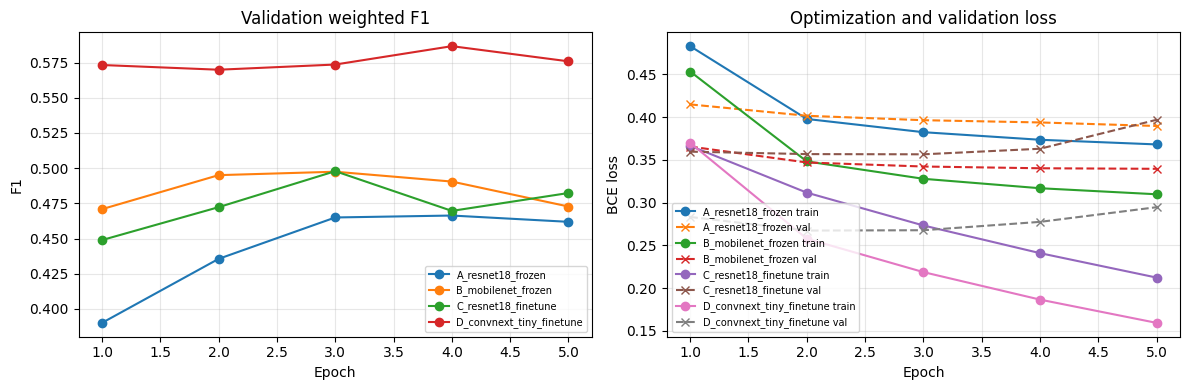

In [9]:
history = pd.concat(histories.values(), ignore_index=True)
history.to_csv(OUT_DIR / 'all_experiments_history.csv', index=False)
best_rows = history.loc[history.groupby('experiment')['weighted_f1'].idxmax()].copy()
best_rows = best_rows.sort_values('weighted_f1', ascending=False).reset_index(drop=True)
display(best_rows[['experiment', 'epoch', 'threshold', 'weighted_f1', 'macro_f1', 'micro_f1', 'val_loss']].round(4))
winner = best_rows.iloc[0]['experiment']
selection = {'chosen_experiment': winner, 'selection_rule': 'highest validation inverse-frequency-weighted F1',
             'validation_epoch': int(best_rows.iloc[0]['epoch']),
             'validation_threshold': float(best_rows.iloc[0]['threshold']), 'seed': SEED}
(OUT_DIR / 'selection.json').write_text(json.dumps(selection, indent=2))
print('Selected from validation only:', selection)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, frame in history.groupby('experiment'):
    axes[0].plot(frame['epoch'], frame['weighted_f1'], marker='o', label=name)
    axes[1].plot(frame['epoch'], frame['train_loss'], marker='o', label=f'{name} train')
    axes[1].plot(frame['epoch'], frame['val_loss'], marker='x', linestyle='--', label=f'{name} val')
axes[0].set(title='Validation weighted F1', xlabel='Epoch', ylabel='F1')
axes[1].set(title='Optimization and validation loss', xlabel='Epoch', ylabel='BCE loss')
for ax in axes: ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT_DIR / 'validation_comparison.png', dpi=150)
plt.show()


From the results above,we can see, method D works best, so we choose D as selected model and later in step 10 we will analyse its per-class performances.

## 10. Which classes work well?

An overall F1 can hide large differences between classes. Here we reload the selected checkpoint(i.e.Method D) and look at the ten strongest and weakest classes on the validation set, together with the number of positive examples. The full 80-class table is saved as a CSV. This analysis does not use test labels.

In [10]:
def load_checkpoint(experiment_key):
    checkpoint = torch.load(OUT_DIR / f'{experiment_key}.pt', map_location='cpu', weights_only=False)
    net = build_model(checkpoint['architecture'], pretrained=False)
    net.load_state_dict(checkpoint['state_dict'])
    return net.to(DEVICE).eval(), checkpoint

selected_model, selected_checkpoint = load_checkpoint(winner)
selected_threshold = float(selected_checkpoint['threshold'])
selected_val_loss, selected_probs, selected_truth = evaluate(selected_model, make_loader(val_dataset, next(spec['batch_size'] for spec in EXPERIMENTS if spec['key'] == winner)))
selected_metrics = compute_metrics(selected_truth, selected_probs, selected_threshold)
per_class = pd.DataFrame({'class_id': np.arange(NUM_CLASSES), 'class_name': CLASSES,
                          'val_support': selected_truth.sum(axis=0).astype(int),
                          'precision': selected_metrics['class_precision'],
                          'recall': selected_metrics['class_recall'],
                          'f1': selected_metrics['class_f1']})
per_class.to_csv(OUT_DIR / 'selected_model_per_class_validation.csv', index=False)
display(per_class.sort_values('f1').head(10).round(3))
display(per_class.sort_values('f1', ascending=False).head(10).round(3))
print('Selected validation weighted/macro/micro F1:',
      *(round(selected_metrics[key], 4) for key in ('weighted_f1', 'macro_f1', 'micro_f1')))
del selected_model
torch.cuda.empty_cache()


,class_id,class_name,val_support,precision,recall,f1
78,78,hair drier,26,1.000,0.038,0.074
70,70,toaster,20,0.143,0.050,0.074
24,24,backpack,619,0.414,0.297,0.346
26,26,handbag,796,0.590,0.358,0.446
67,67,cell phone,555,0.533,0.391,0.451
76,76,scissors,110,0.600,0.382,0.467
44,44,spoon,391,0.476,0.522,0.498
58,58,potted plant,470,0.468,0.536,0.500
79,79,toothbrush,109,0.717,0.394,0.509
47,47,apple,167,0.725,0.395,0.512


,class_id,class_name,val_support,precision,recall,f1
23,23,giraffe,290,0.993,0.969,0.981
38,38,tennis racket,375,0.958,0.965,0.961
22,22,zebra,222,0.972,0.937,0.954
20,20,elephant,233,0.973,0.931,0.952
4,4,airplane,343,0.969,0.918,0.943
21,21,bear,102,0.957,0.873,0.913
33,33,kite,260,0.935,0.881,0.907
6,6,train,407,0.934,0.875,0.904
61,61,toilet,407,0.927,0.867,0.896
15,15,cat,465,0.874,0.867,0.870


Selected validation weighted/macro/micro F1: 0.5865 0.6821 0.7117


## 11. Test predictions

Only after validation-based selection do we run inference on the unlabelled test images. The cell below generates a JSON file for each of A-D from its saved checkpoint and validation threshold, and copies the chosen model's output to `selected_test_predictions.json`. Each JSON key is an image stem without `.jpg`; each value is a list of zero-based class IDs. The assertions check the 4,952-image count and output format.

The saved output below came from a resumed session, so A-C JSONs were reused there. On a fresh run, the updated code regenerates all four files. Test-only server scores are reported separately and do not change the validation-selected model.

In [11]:
@torch.inference_mode()
def predict_test(net, threshold, batch_size):
    predictions = {}
    for images, stems in make_loader(test_dataset, batch_size):
        images = images.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', enabled=True):
            logits = net(images)
        is_positive = torch.sigmoid(logits.float()).cpu().numpy() >= threshold
        for stem, row in zip(stems, is_positive):
            predictions[str(stem)] = np.flatnonzero(row).astype(int).tolist()
    assert len(predictions) == len(test_dataset) == 4_952
    assert all(len(k) == 12 and all(0 <= c < NUM_CLASSES for c in values)
               for k, values in predictions.items())
    return predictions

for spec in EXPERIMENTS:
    key = spec['key']
    destination = OUT_DIR / f'{key}_test_predictions.json'
    net, checkpoint = load_checkpoint(key)
    predictions = predict_test(net, float(checkpoint['threshold']), min(spec['batch_size'], 32))
    destination.write_text(json.dumps(predictions, indent=2))
    print(key, '=>', destination, 'images:', len(predictions),
          'mean predicted labels:', round(np.mean([len(x) for x in predictions.values()]), 3))
    if key == winner:
        (OUT_DIR / 'selected_test_predictions.json').write_text(json.dumps(predictions, indent=2))
    del net
    torch.cuda.empty_cache()
print('Validation-selected JSON:', OUT_DIR / 'selected_test_predictions.json')

Reusing existing test JSON: /content/drive/MyDrive/IAV_MS_COCO/A_resnet18_frozen_test_predictions.json
Reusing existing test JSON: /content/drive/MyDrive/IAV_MS_COCO/B_mobilenet_frozen_test_predictions.json
Reusing existing test JSON: /content/drive/MyDrive/IAV_MS_COCO/C_resnet18_finetune_test_predictions.json
D_convnext_tiny_finetune => /content/drive/MyDrive/IAV_MS_COCO/D_convnext_tiny_finetune_test_predictions.json images: 4952 mean predicted labels: 2.555
Validation-selected JSON: /content/drive/MyDrive/IAV_MS_COCO/selected_test_predictions.json


### Optional test-only evaluation

The code below submits each of the 4 exported JSON files to the course evaluation endpoint with group name just4test. It sends the form's name, descr, file and submit fields only; the update checkbox field is omitted, so this is a test-only assessment and does not update the public leaderboard. These test results are descriptive and cannot alter model selection or thresholds. 

`RUN_TEST_ONLY` is `False` by default, so **Run all** stops short of sending any request. Set it to `True` only if you want to repeat the four test-only evaluations; change `GROUP_NAME` first if needed. The output saved in this notebook is from our earlier request for D; the A-C requests were made in a previous session.

In [12]:
RUN_TEST_ONLY = False  # Set True to send test-only requests for all four methods.
GROUP_NAME = 'just4test'
EVAL_URL = 'https://www.creatis.insa-lyon.fr/kechichian/ms-coco-classif-leaderboard.py'

if RUN_TEST_ONLY:
    import requests
    from bs4 import BeautifulSoup
    reports_path = OUT_DIR / 'test_only_server_reports.json'
    test_only_reports = json.loads(reports_path.read_text()) if reports_path.exists() else {}
    for spec in EXPERIMENTS:
        key = spec['key']
        path = OUT_DIR / f'{key}_test_predictions.json'
        assert path.exists(), f'Generate predictions for {key} before server evaluation.'
        form = {'name': GROUP_NAME, 'descr': key, 'submit': 'Submit !'}
        assert 'update' not in form and 'show' not in form
        with path.open('rb') as prediction_file:
            response = requests.post(
                EVAL_URL, data=form,
                files={'file': (path.name, prediction_file, 'application/json')},
                timeout=180)
        response.raise_for_status()
        report = BeautifulSoup(response.text, 'html.parser').get_text(' ', strip=True)
        test_only_reports[key] = report
        print(key, 'HTTP', response.status_code, report[:1500], flush=True)
    reports_path.write_text(json.dumps(test_only_reports, indent=2, ensure_ascii=False))
else:
    print('Test-only server requests skipped. Set RUN_TEST_ONLY = True to run them.')

D_convnext_tiny_finetune HTTP 200 MS COCO multi-task classification challenge MS COCO multi-task classification challenge Submission file 'D_convnext_tiny_finetune_test_predictions.json' for just4test uploaded successfully on 08-10-2026 20:20:46 Evaluation results Mean metrics Metric Value accuracy 0.6629 f1 0.5508 precision 0.5864 recall 0.5193 Mean precision and recall are calculated as weighted averages of class precision and recall, where weights are normalized inverse class frequenies.


1946

## 12. Results and discussion

**Choosing an epoch and threshold.** Our first A-C run chose epochs with thresholds only up to 0.70 and recalibrated those saved checkpoints afterward. That was inconsistent: a wider threshold grid might favour a different epoch. We reran A-C and evaluated the 0.10-0.95 grid at every epoch. D followed that same validation procedure. The table shows the best epoch for each method.

| Method | Epoch | Threshold | Weighted F1 | Macro F1 | Micro F1 | Validation loss |
|---|---:|---:|---:|---:|---:|---:|
| A: frozen ResNet-18 | 4 | 0.875 | 0.4664 | 0.5264 | 0.5711 | 0.3937 |
| B: frozen MobileNetV3-Large | 3 | 0.875 | 0.4975 | 0.5871 | 0.6297 | 0.3422 |
| C: fine-tuned ResNet-18 | 3 | 0.875 | 0.4978 | 0.5762 | 0.6266 | 0.3565 |
| D: fine-tuned ConvNeXt-Tiny | **4** | **0.925** | **0.5866** | **0.6822** | **0.7118** | **0.2775** |

We selected **D, epoch 4, threshold 0.925** because its validation weighted F1 is 0.0888 above the best A-C result. Its macro and micro F1 are also higher. Epoch 5 has a lower training loss (0.1595 versus 0.1867), but its validation loss rises from 0.2775 to 0.2947 and weighted F1 falls to 0.5758. This is why we kept the epoch-4 checkpoint. The comparison does not isolate the effect of backbone architecture from model capacity and fine-tuning choices.

**Class-level results.** With D, giraffe (F1 0.981; 290 validation positives), tennis racket (0.961; 375), and zebra (0.954; 222) work well. Hair drier and toaster each reach only about 0.074 F1, with 26 and 20 positives. Backpack is also difficult (0.346; 619 positives), so frequency is not the whole explanation. A second validation pass gave weighted F1 0.5865 rather than 0.5866 because of a small mixed-precision numerical difference; the saved checkpoint was chosen from the training-time pass.

**Test-only scores.** We sent prediction JSONs under `just4test` without the leaderboard-update field. These scores were recorded after validation-based selection; we did not tune thresholds or change the selected checkpoint in response to them,otherwise our model risk changing the test set into another train set.

| Method | Test F1 | Precision | Recall | Accuracy |
|---|---:|---:|---:|---:|
| A | 0.4451 | 0.4639 | 0.4277 | 0.5298 |
| B | 0.4552 | 0.4586 | 0.4518 | 0.6082 |
| C | 0.4821 | 0.4940 | 0.4707 | 0.6073 |
| D | **0.5508** | **0.5864** | **0.5193** | **0.6629** |

D was added after we had already seen A-C test-only scores. Its test score is useful as a descriptive check, but this sequence weakens any claim that the test comparison is a completely untouched estimate. The exact responses from our run are saved in `test_only_server_reports.json` in our Drive output folder; this table keeps the main numbers in the notebook itself.

This experiment uses one random split, so it does not quantify variability across splits. Resizing every image to 224 x 224 distorts aspect ratios; one threshold cannot suit every class; and loss weights are capped at 20. We cannot inspect test labels locally, so the detailed error analysis is based on validation data.